# 04 · Text Preprocessing — from raw reviews to model-ready text
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.** Previous: [03 Vocabulary](03_eda_vocabulary_ngrams.ipynb).

EDA told us what is wrong with the raw text (HTML, digits, punctuation, CAPS, contractions). Here we build a cleaning pipeline step by step, *measure* what each step does, and save the cleaned data.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, html, string, time, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from nltk.stem import PorterStemmer
sns.set_theme(style='whitegrid')
df = pd.read_csv('data/imdb_dedup.csv')
print(df.shape)

(49582, 3)


In [2]:
sample = df['review'].iloc[1]
print(sample)

A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.


## 1. Cleaning steps, one at a time

### Step 1 — decode HTML entities and strip tags

In [3]:
def strip_html(s):
    s = html.unescape(s)
    return re.sub(r'<[^>]+>', ' ', s)
print(strip_html(sample)[:300])

A wonderful little production.   The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece.   The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the v


### Step 2 — remove URLs

In [4]:
def strip_urls(s): return re.sub(r'http\S+|www\.\S+', ' ', s)
strip_urls('see http://imdb.com/title and www.foo.org now')

'see   and   now'

### Step 3 — lower-case

In [5]:
def lower(s): return s.lower()
lower('This Movie was GREAT')

'this movie was great'

### Step 4 — expand contractions (so *don't* → *do not* and negation is explicit)

In [6]:
CONTR = {"won't":'will not',"can't":'can not',"n't":' not',"'re":' are',"'ve":' have',"'ll":' will',"'d":' would',"'m":' am',"it's":'it is',"that's":'that is',"what's":'what is',"there's":'there is',"he's":'he is',"she's":'she is',"let's":'let us'}
def expand(s):
    for k,v in CONTR.items(): s = s.replace(k,v)
    return s
expand("i don't think it's good, can't recommend, won't watch again")

'i do not think it is good, can not recommend, will not watch again'

### Step 5 — handle emphasis: shortened elongated words (*sooooo* → *soo*)

In [7]:
def squeeze(s): return re.sub(r'(.)\1{2,}', r'\1\1', s)
squeeze('sooooo gooood!!!')

'soo good!!'

### Step 6 — keep only letters (drop digits & punctuation)

In [8]:
def letters(s): return re.sub(r'[^a-z\s]', ' ', s)
letters('great 10/10 movie!!! (wow)')

'great       movie     wow '

### Step 7 — collapse whitespace

In [9]:
def squash(s): return re.sub(r'\s+', ' ', s).strip()
squash('  a   b \n c ')

'a b c'

### Step 8 — stop-word removal (keeping negations)

In [10]:
STOP = set(ENGLISH_STOP_WORDS) - {'not','no','nor','never','nothing','cannot'}
def rm_stop(s): return ' '.join(w for w in s.split() if w not in STOP)
rm_stop('this is not a good movie at all')

'not good movie'

### Step 9 — stemming (Porter)

In [11]:
ps = PorterStemmer()
for w in ['running','movies','acting','acted','beautifully','boring','wonderful']: print(f'{w:12s}→ {ps.stem(w)}')

running     → run
movies      → movi
acting      → act
acted       → act
beautifully → beauti
boring      → bore
wonderful   → wonder


In [12]:
_cache={}
def stem(s):
    out=[]
    for w in s.split():
        if w not in _cache: _cache[w]=ps.stem(w)
        out.append(_cache[w])
    return ' '.join(out)
stem('the actors were acting beautifully')

'the actor were act beauti'

## 2. Combine into one pipeline

In [13]:
def clean_basic(s):
    return squash(letters(squeeze(expand(lower(strip_urls(strip_html(s)))))))
def clean_nostop(s): return rm_stop(clean_basic(s))
def clean_stem(s):  return stem(clean_nostop(s))
print(clean_basic(sample)[:300]); print(); print(clean_nostop(sample)[:300]); print(); print(clean_stem(sample)[:300])

a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down p

wonderful little production filming technique unassuming old time bbc fashion gives comforting discomforting sense realism entire piece actors extremely chosen michael sheen not got polari voices pat truly seamless editing guided references williams diary entries not worth watching terrificly writte

wonder littl product film techniqu unassum old time bbc fashion give comfort discomfort sens realism entir piec actor extrem chosen michael sheen not got polari voic pat truli seamless edit guid refer william diari entri not worth watch terrificli written perform piec master product great master s c


## 3. Apply to all 49,582 reviews

In [14]:
t=time.time(); df['clean'] = df['review'].apply(clean_basic); print(f'basic: {time.time()-t:.1f}s')

basic: 11.5s


In [15]:
t=time.time(); df['clean_nostop'] = df['clean'].apply(rm_stop); print(f'no-stop: {time.time()-t:.1f}s')

no-stop: 2.0s


In [16]:
t=time.time(); df['clean_stem'] = df['clean_nostop'].apply(stem); print(f'stem: {time.time()-t:.1f}s')

stem: 4.4s


In [17]:
df[['review','clean','clean_nostop','clean_stem']].head(3).T

,0,1,2
review,One of the other reviewers has mentioned that ...,A wonderful little production. <br /><br />The...,I thought this was a wonderful way to spend ti...
clean,one of the other reviewers has mentioned that ...,a wonderful little production the filming tech...,i thought this was a wonderful way to spend ti...
clean_nostop,reviewers mentioned watching just oz episode h...,wonderful little production filming technique ...,thought wonderful way spend time hot summer we...
clean_stem,review mention watch just oz episod hook right...,wonder littl product film techniqu unassum old...,thought wonder way spend time hot summer weeke...


## 4. Effect of each step on text size

In [18]:
for c in ['review','clean','clean_nostop','clean_stem']:
    df['len_'+c] = df[c].str.split().str.len()
summary = df[['len_review','len_clean','len_clean_nostop','len_clean_stem']].mean().round(1).to_frame('avg words'); summary

,avg words
len_review,231.4
len_clean,234.4
len_clean_nostop,110.2
len_clean_stem,110.2


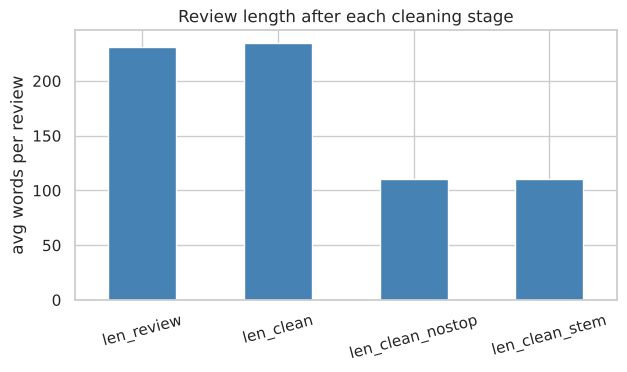

In [19]:
summary.plot(kind='bar', legend=False, color='steelblue', figsize=(7,3.5)); plt.ylabel('avg words per review'); plt.xticks(rotation=15); plt.title('Review length after each cleaning stage'); plt.show()

In [20]:
for c in ['clean','clean_nostop','clean_stem']:
    v = set(w for t in df[c] for w in t.split()); print(f'{c:14s} vocabulary = {len(v):,}')

clean          vocabulary = 99,509


clean_nostop   vocabulary = 99,201


clean_stem     vocabulary = 68,914


In [21]:
empty = (df['clean_nostop'].str.strip()=='').sum(); print('Reviews that became empty after stop-word removal:', empty)

Reviews that became empty after stop-word removal: 0


## 5. Does cleaning actually help? (measured, not assumed)

We train the same TF-IDF + Logistic Regression model on each variant, using the shared 80/20 split.

In [22]:
tr_idx, te_idx = train_test_split(df.index, test_size=.2, stratify=df['label'], random_state=42)
def score(col, **kw):
    t=time.time()
    vec = TfidfVectorizer(max_features=50000, **kw)
    Xtr = vec.fit_transform(df.loc[tr_idx,col]); Xte = vec.transform(df.loc[te_idx,col])
    clf = LogisticRegression(max_iter=1000, C=4).fit(Xtr, df.loc[tr_idx,'label'])
    return round(clf.score(Xte, df.loc[te_idx,'label']),4), Xtr.shape[1], round(time.time()-t,1)
res={}
res['raw (no cleaning)'] = score('review')
res['basic clean'] = score('clean')
res['+ stop-words removed'] = score('clean_nostop')
res['+ stemming'] = score('clean_stem')
res_df = pd.DataFrame(res, index=['accuracy','n_features','seconds']).T; res_df

,accuracy,n_features,seconds
raw (no cleaning),0.9006,50000.0,18.8
basic clean,0.9017,50000.0,17.6
+ stop-words removed,0.8996,50000.0,8.4
+ stemming,0.8952,50000.0,10.3


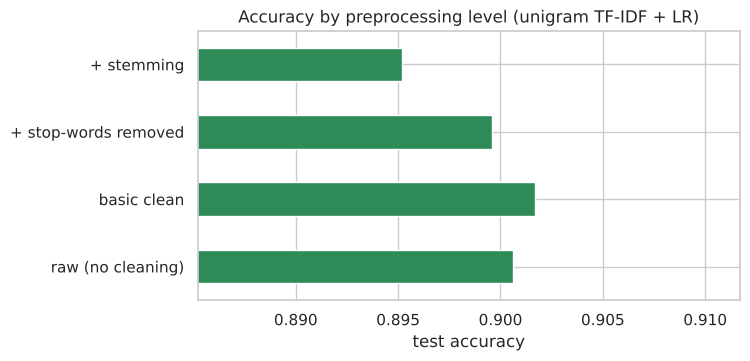

In [23]:
res_df['accuracy'].plot(kind='barh', color='seagreen', figsize=(7,3.5)); plt.xlim(res_df.accuracy.min()-.01, res_df.accuracy.max()+.01); plt.xlabel('test accuracy'); plt.title('Accuracy by preprocessing level (unigram TF-IDF + LR)'); plt.show()

### 5.1 Does keeping negations / n-grams matter?

In [24]:
res2={}
res2['basic, unigrams'] = score('clean')
res2['basic, uni+bigrams'] = score('clean', ngram_range=(1,2))
res2['no-stop, uni+bigrams'] = score('clean_nostop', ngram_range=(1,2))
res2['stemmed, uni+bigrams'] = score('clean_stem', ngram_range=(1,2))
pd.DataFrame(res2, index=['accuracy','n_features','seconds']).T

,accuracy,n_features,seconds
"basic, unigrams",0.9017,50000.0,15.3
"basic, uni+bigrams",0.9108,50000.0,53.8
"no-stop, uni+bigrams",0.9057,50000.0,38.3
"stemmed, uni+bigrams",0.9026,50000.0,33.9


### 5.2 Remove negations too — what breaks?

In [25]:
STOP_ALL = set(ENGLISH_STOP_WORDS)
df['clean_dropneg'] = df['clean'].apply(lambda s: ' '.join(w for w in s.split() if w not in STOP_ALL))
print('keeping negations     :', score('clean_nostop', ngram_range=(1,2))[0])
print('removing negations too:', score('clean_dropneg', ngram_range=(1,2))[0])

keeping negations     : 0.9057


removing negations too: 0.9036


## 6. Look at what the pipeline did to specific tricky reviews

In [26]:
tricky = df[df['review'].str.contains("n't")].head(2)
for _,r in tricky.iterrows(): print('RAW  :', r['review'][:250].replace('\n',' ')); print('CLEAN:', r['clean'][:250]); print()

RAW  : One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of 
CLEAN: one of the other reviewers has mentioned that after watching just oz episode you will be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its brutality and unflinching scenes of violence which

RAW  : This show was an amazing, fresh & innovative idea in the 70's when it first aired. The first 7 or 8 years were brilliant, but things dropped off after that. By 1990, the show was not really funny anymore, and it's continued its decline further to the
CLEAN: this show was an amazing fresh innovative idea in the s when it first aired the first or years were brilliant but things dropped off after that by the show was not really funny anymore and it is continued its decline f

In [27]:
df[df['review'].str.contains('http')]['review'].head(2).tolist()

["Following directly from where the story left off in part one, the second half which sets about telling the inevitable downfall and much more grim side of the man's legacy is exactly as such. In direct contrast to the first feature, part two represents a shift from Che the pride and glory of a revolutionised country, to Che\x97struggling liberator of a country to which he has no previous ties. The change of setting isn't just aesthetic; from the autumn and spring greys of the woodlands comes a change of tone and heart to the feature, replacing the optimism of the predecessor with a cynical, battered and bruised reality aligned to an all new struggle. Yet, as Che would go on to say himself\x97such a struggle is best told exactly as that\x97a struggle. While Part One certainly helped document that initial surge to power that the revolutionary guerrilla acquired through just that, Part Two takes a much more refined, callous and bleak segment of Che's life and ambition, and gives it an as

## 7. Save cleaned data

In [28]:
out = df[['review','sentiment','label','clean','clean_nostop','clean_stem']]
out.to_csv('data/imdb_clean.csv', index=False)
print(out.shape)

(49582, 6)


In [29]:
import os; print(round(os.path.getsize('data/imdb_clean.csv')/1e6,1),'MB')

198.6 MB


## 8. Summary
| Stage | What it does |
|---|---|
| HTML / URL strip | removes `<br />` etc. |
| lower-case + contractions | `don't` → `do not` |
| elongation squeeze | `sooooo` → `soo` |
| letters only | no digits / punctuation |
| stop-words (keep negations) | shrinks text ~50% |
| stemming | merges word forms |

See the accuracy table above for which choices helped (all measured on the same split).

**Next:** [05 – Classical ML](05_classical_ml_models.ipynb)